# ASMSA v2 &mdash; Tune

&#8592; [Prepare](02-prepare.ipynb) &nbsp;|&nbsp; [Train](04-train.ipynb) &#8594;

| | |
|---|---|
| **What it does** | Search architectures and objectives, scoring each trial by how well its latent space matches the prior. |
| **Typical runtime** | minutes to hours &mdash; you set the budget |
| **Needs** | <code>features.pt</code> and <code>split.npz</code> from <a href='02-prepare.ipynb'>02-prepare</a> |
| **Produces** | <code>tuning.json</code> |

---

Tuning is **optional**: [04-train](04-train.ipynb) falls back to sensible defaults if
you skip it. It is worth doing because the latent-regularizer choice and its weight
change results far more than the layer widths do.

> *Note on v1:* v1's tuner was built on keras-tuner with a Kubernetes job submitter, so
> it could not survive the move to PyTorch and only ran on one specific cluster. This
> uses Optuna locally: its TPE sampler beats random search at equal budget, and its
> pruner abandons hopeless trials instead of running every one to the full epoch count.
> **v1's scoring criterion is preserved exactly** &mdash; see below.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

import asmsa_v2 as asmsa
from asmsa_v2.tune import MEDIUM_SPACE, SMALL_SPACE, SearchSpace, TuningAnalyzer, tune
from asmsa_v2.viz import use_asmsa_style

use_asmsa_style()
project = asmsa.Project.load('run')

bundle = torch.load(project.features_file, weights_only=False)
Xs = bundle['features']
sp = np.load(project.split_file, allow_pickle=False)

train_tensors = {'complex': Xs[sp['train']]}
val_tensors = {'complex': Xs[sp['val']]}
print(f"train {tuple(train_tensors['complex'].shape)}  "
      f"val {tuple(val_tensors['complex'].shape)}")

train (35001, 596)  val (7500, 596)


## 1. What to score a trial on

| Objective | Direction | What it measures | Use when |
|---|---|---|---|
| `kl` | minimize | k-NN KL divergence between the prior and the latent distribution, averaged over the tail of training and penalized by its variance. **This is v1's criterion, reproduced exactly.** | Default. It measures what the adversarial/MMD penalty is actually trying to achieve, and the variance term rejects models whose latent never settles. |
| `val_recon` | minimize | Best validation reconstruction loss. | You care mainly about faithful reconstruction, e.g. to decode latent points back to structures. |
| `vamp2` | maximize | VAMP-2 score: how much of the system's *slow* dynamics the latent resolves. | You want the CVs for enhanced sampling. The slow coordinates are exactly the ones metadynamics must push along. |
| `composite` | minimize | `kl + val_recon - (vamp2 - 1)/latent_dim`. | You want a balance and have no strong preference. |

Reconstruction loss alone is a poor selector: a model can lower it while abandoning the
prior shape entirely, leaving a latent that metadynamics cannot grid.

In [2]:
OBJECTIVE = 'kl'      # 'kl' | 'val_recon' | 'vamp2' | 'composite'

N_TRIALS = 20         # raise this once you have seen how long one trial takes
EPOCHS = 30           # per trial; shorter than the final training run on purpose
VAMP_LAG = 20         # frames; only used by 'vamp2' and 'composite'
N_JOBS = 1            # parallel trials

print(f'budget: {N_TRIALS} trials x {EPOCHS} epochs')

budget: 20 trials x 30 epochs


## 2. The search space

Architectures are parameterized the way v1 did it &mdash; a *seed* width halved per
layer &mdash; so hyperparameter ranges published for v1 transfer directly.

In a `SearchSpace`, a tuple means *search over these* and a scalar means *fix at this*.
For `lr_ae`, `lr_d` and `lam_latent` a 2-tuple is a continuous log-uniform range.

The most consequential axis is `latent_reg`:

| Value | What it does |
|---|---|
| `adversarial` | The classic AAE: a discriminator learns to tell prior samples from latent codes. Expressive, but a minimax game to balance. |
| `mmd` | Wasserstein-autoencoder kernel penalty (Tolstikhin et al., ICLR 2018). No discriminator, no balancing, and markedly less prone to collapsing a 2-D latent. |
| `sliced` | Sliced-Wasserstein penalty (Kolouri et al., 2018). Like `mmd` but with no kernel bandwidth to choose &mdash; near-exact in 2-D. |

In [3]:
space = SearchSpace(
    ae_neuron_seed=(32, 64, 96, 128),   # encoder width; halved per layer
    ae_layers=(2, 3, 4),
    disc_neuron_seed=(32, 64, 96),
    disc_layers=(2, 3),
    activation=('gelu', 'silu'),
    latent_dim=project.latent_dim,      # fixed: the CV count is a design decision

    batch_size=(64, 128, 256),
    lr_ae=(1e-4, 1e-3),                 # log-uniform range
    lr_d=(5e-5, 5e-4),

    latent_reg=('adversarial', 'mmd', 'sliced'),
    lam_latent=(0.1, 20.0),             # weight of the prior-matching penalty
    recon_loss=('mse', 'huber'),
)

# Ready-made alternatives mirroring v1's presets:
#   space = SMALL_SPACE     # quick, narrow
#   space = MEDIUM_SPACE    # broad
print('discrete combinations:', space.size(), '(inf = has continuous axes)')

discrete combinations: inf (inf = has continuous axes)


## 3. Run the search

Trials run sequentially by default. Pruning stops a trial whose score is clearly behind
the median of its peers at the same epoch, which typically reclaims a third of the
budget &mdash; pruned trials still appear in the results, marked `pruned`.

In [4]:
result = tune(
    train_tensors, val_tensors,
    prior_factory=project.make_prior,
    space=space,
    n_trials=N_TRIALS,
    epochs=EPOCHS,
    objective=OBJECTIVE,
    vamp_lag=VAMP_LAG,
    kl_threshold=0.25,        # ignore the first quarter of epochs, as v1 did
    n_jobs=N_JOBS,
    prune=True,
    seed=0,
    out_dir=project.dir('tuning'),
    extra_train_kwargs=dict(time_lagged=bool(project.time_lag)),
)
print(f'saved {project.tuning_file}')
result

  0%|          | 0/20 [00:00<?, ?it/s]

saved /home/tedeschg/prj/ASMSA_v2/notebooks/run/02-tuning/tuning.json


trial,score,latent_reg,lam_latent,ae_neuron_seed,ae_layers,disc_neuron_seed,disc_layers,batch_size,lr_ae,lr_d,activation,recon_loss
#14,0.1945,mmd,13.81,128,3,64,2,256,0.0001495,8.128e-05,gelu,huber
#2,0.2391,mmd,17.68,96,4,64,2,256,0.0001572,0.0001169,gelu,huber
#18,0.2642,mmd,14.94,128,3,64,2,256,0.0001799,0.0002658,gelu,huber
#19,0.2941,mmd,13.1,128,3,64,2,256,0.0002267,6.967e-05,gelu,huber
#17,0.3118,mmd,16.71,64,3,64,2,64,0.0003693,8.577e-05,gelu,huber
#12,0.3922,mmd,9.529,128,4,64,2,256,0.0001422,0.0001097,gelu,huber
#4,0.4223,mmd,15.85,128,4,96,3,256,0.0006513,0.0001246,gelu,mse
#10,0.4306,sliced,2.105,96,2,64,2,256,0.0003132,9.53e-05,gelu,huber
#1,0.5060,mmd,0.198,96,4,64,2,128,0.0004806,0.0001144,silu,huber
#0,0.8579,mmd,1.153,64,3,64,2,128,0.0001178,6.111e-05,silu,mse


## 4. Did the budget suffice?

**What to look for:** the running-best curve should *flatten*. If it is still improving
at the last trial, raise `N_TRIALS` &mdash; you stopped while still finding better
models.

In the per-trial curve panel, a good trial's KL curve is smooth and settled beyond
roughly the 20th epoch. One still oscillating at the end never converged, whatever its
final score; prefer a slightly worse but stable trial over a better but erratic one.

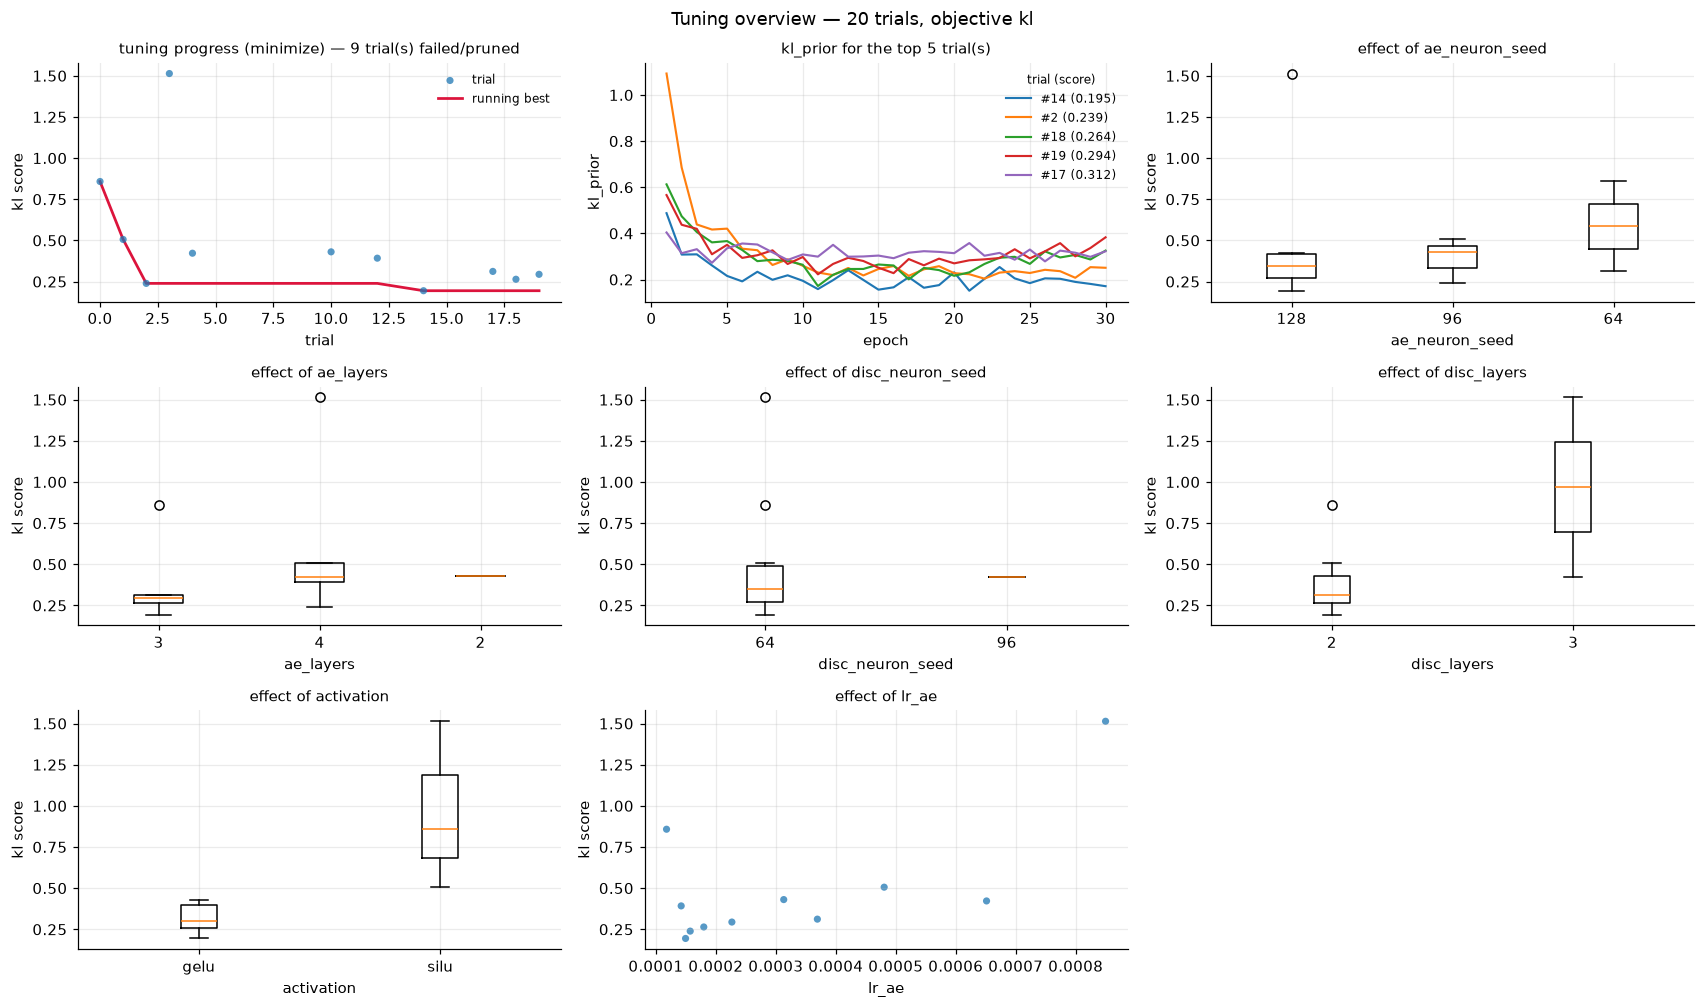

In [5]:
analyzer = TuningAnalyzer(result)
fig = analyzer.plot_overview()
plt.show()

### The leaderboard

Best row highlighted. Compare the top few rather than fixating on the winner: if trials
2&ndash;5 differ wildly in their hyperparameters but score alike, the search is telling
you those axes do not matter much for this system.

In [6]:
analyzer.table(10)

,number,score,state,duration_s,ae_neuron_seed,ae_layers,disc_neuron_seed,disc_layers,activation,batchnorm,...,weight_decay,grad_clip,latent_reg,lam_latent,recon_loss,label_smoothing,r1_gamma,metric_kl_tail,metric_kl_final,metric_val_recon
0,14,0.194510,complete,59.6,128,3,64,2,gelu,True,...,0.0,5.0,mmd,13.812453,huber,0.0,0.0,0.194510,0.171117,0.383294
1,2,0.239057,complete,83.1,96,4,64,2,gelu,True,...,0.0,5.0,mmd,17.683025,huber,0.0,0.0,0.239057,0.250924,0.387515
2,18,0.264226,complete,60.4,128,3,64,2,gelu,True,...,0.0,5.0,mmd,14.943055,huber,0.0,0.0,0.264226,0.325399,0.384337
3,19,0.294123,complete,59.8,128,3,64,2,gelu,True,...,0.0,5.0,mmd,13.095491,huber,0.0,0.0,0.294123,0.382889,0.382910
4,17,0.311788,complete,215.8,64,3,64,2,gelu,True,...,0.0,5.0,mmd,16.713717,huber,0.0,0.0,0.311788,0.322441,0.381454
5,12,0.392188,complete,64.0,128,4,64,2,gelu,True,...,0.0,5.0,mmd,9.528546,huber,0.0,0.0,0.392188,0.291845,0.383902
6,4,0.422320,complete,63.3,128,4,96,3,gelu,True,...,0.0,5.0,mmd,15.848097,mse,0.0,0.0,0.422320,0.383143,0.890018
7,10,0.430578,complete,19.8,96,2,64,2,gelu,True,...,0.0,5.0,sliced,2.105395,huber,0.0,0.0,0.430578,0.372024,0.377462
8,1,0.505988,complete,176.9,96,4,64,2,silu,True,...,0.0,5.0,mmd,0.197999,huber,0.0,0.0,0.505988,0.517648,0.372344
9,0,0.857881,complete,116.7,64,3,64,2,silu,True,...,0.0,5.0,mmd,1.153129,mse,0.0,0.0,0.857881,0.706495,0.896175


In [7]:
analyzer.print_best(3)

--- trial #14   score=0.19451   (60s)
      activation           gelu
      ae_layers            3
      ae_neuron_seed       128
      batch_size           256
      batchnorm            True
      disc_layers          2
      disc_neuron_seed     64
      grad_clip            5.0
      label_smoothing      0.0
      lam_latent           13.81245325016088
      latent_dim           2
      latent_reg           mmd
      lr_ae                0.00014949636471384584
      lr_d                 8.127720099471854e-05
      r1_gamma             0.0
      recon_loss           huber
      weight_decay         0.0
      metrics: kl_final=0.1711, kl_tail=0.1945, val_recon=0.3833
--- trial #2   score=0.23906   (83s)
      activation           gelu
      ae_layers            4
      ae_neuron_seed       96
      batch_size           256
      batchnorm            True
      disc_layers          2
      disc_neuron_seed     64
      grad_clip            5.0
      label_smoothing      0.0
      lam_

### Which setting actually mattered?

A box plot per value. A flat comparison means that axis is irrelevant here and you can
fix it to cut the search space next time.

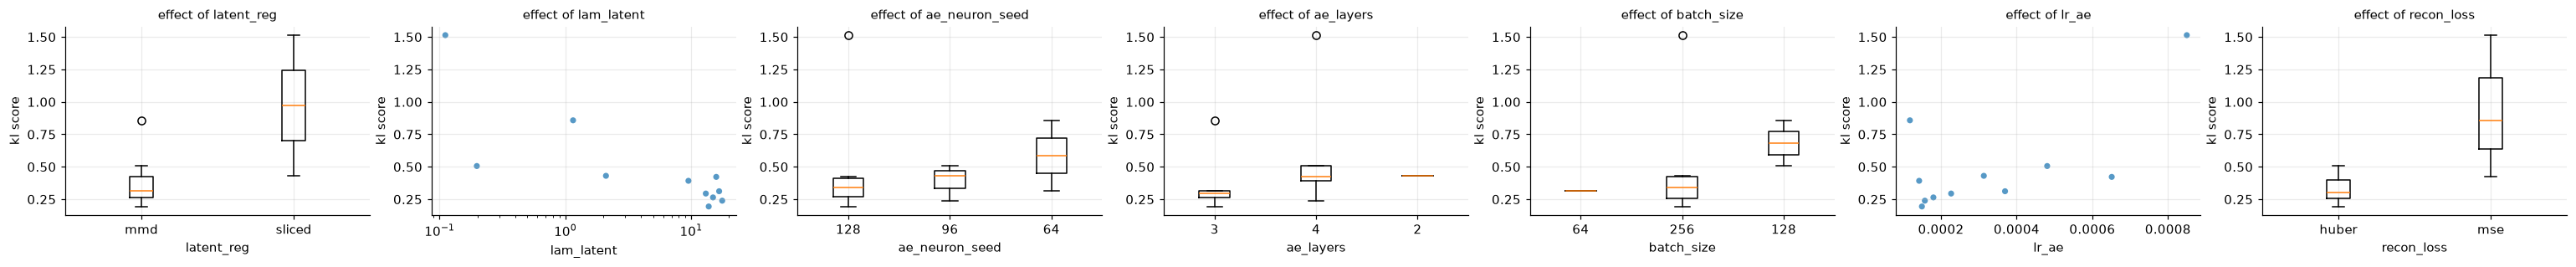

In [8]:
params = [p for p in ('latent_reg', 'lam_latent', 'ae_neuron_seed',
                      'ae_layers', 'batch_size', 'lr_ae', 'recon_loss')
          if len({str(t.params.get(p)) for t in result.trials}) > 1]

if params:
    fig, axes = plt.subplots(1, len(params), figsize=(4.0 * len(params), 3.0),
                             squeeze=False)
    for ax, p in zip(axes[0], params):
        analyzer.plot_param_effect(p, ax=ax)
    plt.tight_layout(); plt.show()
else:
    print('nothing was varied; widen the search space')

## 5. Carry the winner forward

[04-train](04-train.ipynb) reloads `tuning.json` itself, so nothing more is needed here.
This cell just shows what it will pick up.

In [9]:
model_cfg, train_cfg = result.to_configs(epochs=300)
print('ModelConfig')
for k, v in model_cfg.to_dict().items():
    print(f'  {k:<20} {v}')
print('\nTrainConfig (selected fields)')
for k in ('epochs', 'batch_size', 'lr_ae', 'lr_d', 'latent_reg',
          'lam_latent', 'recon_loss'):
    print(f'  {k:<20} {getattr(train_cfg, k)}')

ModelConfig
  latent_dim           2
  encoder_widths       [128, 64, 32]
  decoder_widths       [32, 64, 128]
  disc_widths          [64, 32]
  activation           gelu
  batchnorm            True
  spectral_norm_disc   True

TrainConfig (selected fields)
  epochs               300
  batch_size           256
  lr_ae                0.00014949636471384584
  lr_d                 8.127720099471854e-05
  latent_reg           mmd
  lam_latent           13.81245325016088
  recon_loss           huber


### Re-opening a past tuning run

```python
from asmsa_v2.tune import TuningAnalyzer
analyzer = TuningAnalyzer(project.tuning_file)   # or any tuning.json
analyzer.plot_overview()
```

Results are plain JSON, so they are portable and diffable &mdash; unlike v1, which
unpickled per-trial files from whichever directory had the newest modification time.

---

&#8592; [Prepare](02-prepare.ipynb) &nbsp;|&nbsp; **Next: [Train](04-train.ipynb)** &#8594;